In [1]:
# =============================================================================
# SENSE-LORAKS: Structured Low-Rank Matrix Modeling of Local k-Space Neighborhoods
# combined with SENSE parallel imaging reconstruction from undersampled data.
#
# This code implements the SENSE-LORAKS algorithm, which integrates conventional
# SENSE reconstruction with a low-rank constraint on multi-coil k-space.
# The method uses coil sensitivity maps and applies structured low-rank matrix
# modeling as a regularization to incorporate support, phase, and parallel
# imaging constraints.
#
# The implementation supports Virtual Conjugate Coil (VCC) augmentation and
# iterative refinement via conjugate gradient (CG) updates.
#
# Hyperparameters:
#   VCC       : Enable Virtual Conjugate Coils (bool), improves reconstruction
#               by exploiting k-space conjugate symmetry.
#   R         : Kernel radius for local k-space neighborhoods; larger R
#               captures more spatial context but increases computation.
#   lambda_   : Regularization weight balancing data consistency vs. low-rank
#               constraint; higher values impose stronger low-rank prior.
#   tol       : Convergence tolerance for relative error in iterative updates.
#   max_iter  : Maximum number of iterations allowed for reconstruction loop.
#   r_C       : Target rank for low-rank approximation of k-space patches.
#
# Reference:
#  Kim TH, Setsompop K, & Haldar JP.  "LORAKS makes better SENSE:
#  phase‐constrained partial fourier SENSE reconstruction without phase
#  calibration." Magnetic Resonance in Medicine. 2017;77(3):1021-1035.
# =============================================================================


import numpy as np
from numpy import linalg as LA
from scipy.io import loadmat
from scipy.sparse.linalg import eigsh, eigs
import matplotlib.pyplot as plt
import time

In [3]:


# -------------------------- Library Functions ---------------------------------
def svdsecon(X, k):
    """
    Compute low-rank SVD approximation using top-k singular values.
    """
    m, n = X.shape
    assert k <= m and k <= n, "k must be smaller than min(X.shape)"

    if m <= n:
        # Compute covariance C = X @ X^H for tall or square matrices
        C = X @ X.conj().T
        try:
            eigvals, U = eigsh(C, k=k, which='LM')
        except:
            eigvals, U = eigs(C, k=k, which='LM')
        idx = np.argsort(-np.abs(eigvals))
        eigvals, U = eigvals[idx], U[:, idx]
        s = np.sqrt(np.abs(eigvals))
        V = (X.conj().T @ U) / s[np.newaxis, :]
        S = np.diag(s)
    else:
        # Compute covariance C = X^H @ X for wide matrices
        C = X.conj().T @ X
        try:
            eigvals, V = eigsh(C, k=k, which='LM')
        except:
            eigvals, V = eigs(C, k=k, which='LM')
        idx = np.argsort(-np.abs(eigvals))
        eigvals, V = eigvals[idx], V[:, idx]
        s = np.sqrt(np.abs(eigvals))
        U = (X @ V) / s[np.newaxis, :]
        S = np.diag(s)

    return U, S, V

def ktoM(kdata, R):
    """
    Convert multi-channel kspace to Henkel matrix using circular kernels of radius R.
    """
    H, W, C = kdata.shape
    y, x = np.ogrid[-R:R+1, -R:R+1]
    mask = (x**2 + y**2 <= R**2)
    mask_flat = mask.flatten()
    num_pixels = np.sum(mask_flat)

    num_patches = (H - 2*R) * (W - 2*R)
    patches = np.zeros((num_pixels * C, num_patches), dtype=np.complex64)

    patch_idx = 0
    for i in range(R, H-R):
        for j in range(R, W-R):
            patch_block = kdata[i-R:i+R+1, j-R:j+R+1, :]  # shape (2R+1, 2R+1, C)
            patch_block_flat = patch_block.reshape(-1, C)  # shape (n*n, C)
            masked_patch = patch_block_flat[mask_flat, :]  # circular mask
            patches[:, patch_idx] = masked_patch.T.reshape(-1)
            patch_idx += 1
    return patches

def Mtok(patch_matrix, image_shape, R):
    """
    Reconstruct multi-channel kspace from Henkel matrix.
    """
    H, W, C = image_shape
    y, x = np.ogrid[-R:R+1, -R:R+1]
    mask = (x**2 + y**2 <= R**2)
    mask_flat = mask.flatten()
    num_pixels = np.sum(mask_flat)
    n = 2 * R + 1

    img_recon = np.zeros((H, W, C), dtype=np.complex64)
    weight = np.zeros((H, W, C), dtype=np.float32)

    idx = 0
    for i in range(R, H-R):
        for j in range(R, W-R):
            patch_vec = patch_matrix[:, idx]  # shape (num_pixels * C,)
            # Reshape patch to (C, num_pixels)
            patch_by_channel = patch_vec.reshape(C, num_pixels)

            # Expand masked patch to (C, n*n) by creating n*n zeros and placing the masked values
            patch_block = np.zeros((C, n*n), dtype=np.complex64)
            patch_block[:, mask_flat] = patch_by_channel  # fill masked positions only

            # Reshape to (n, n, C) for direct placement in image
            patch_block_3d = patch_block.T.reshape(n, n, C)

            img_recon[i-R:i+R+1, j-R:j+R+1, :] += patch_block_3d
            weight[i-R:i+R+1, j-R:j+R+1, :] += mask[..., None].astype(np.float32)

            idx += 1

    return img_recon, weight


def ft2_np(data):
    """
    Compute normalized centered 2D Fourier transform (forward).
    """
    nx,ny = data.shape[:2]
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(data),axes=(0,1))) / np.sqrt(nx*ny)

def ift2_np(data):
    """
    Compute normalized centered 2D inverse Fourier transform (backward).
    """
    nx,ny = data.shape[:2]
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(data),axes=(0,1))) * np.sqrt(nx*ny)

def show(img, title):
    """
    Display 2D grayscale image with matplotlib.
    """
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')



#### Required Inputs (`dataset.mat`)

| Name        | Shape              | Description                              |
|-------------|--------------------|------------------------------------------|
| `kData`     | `(nx, ny, nCoils)` | Undersampled multi-coil k-space data     |
| `kMask`     | `(nx, ny)` or `(nx, ny, 1)` or `(nx, ny, nCoils)` | Binary sampling mask         |
| `coil_sens` | `(nx, ny, nCoils)` | Coil sensitivity maps (complex-valued)   |

# Test with kspace and mask numpy file save from script_basic_sense_cs.ipynb

Opening files, getting the kspace from the middle slice and creating the mask

In [9]:
# Mask
msk = np.load("data/msk.npy")
print(msk.shape)
kMask = msk

#kspace
kspace_8st_slice = np.load("data/kspace_8st_slice.npy")
#print(kspace_8st_slice.shape)
# Transpose the k-space data to have coils in the last dimension
kData = np.transpose(kspace_8st_slice, (1,2,0))
print(kData.shape)

# Sensitivity maps
sensitivity_maps_8st_slice = np.load("data/sensitivity_maps_8st_slice.npy")
#print(sensitivity_maps_8st_slice.shape)
coil_sens = np.transpose(sensitivity_maps_8st_slice, (1,2,0))
print(coil_sens.shape)


(320, 320, 1)
(320, 320, 20)
(320, 320, 20)


In [11]:

# -------------------------- Hyperparameters ----------------------------------
VCC = True              # Enable Virtual Conjugate Coils
R = 3                   # Kernel radius
lambda_ = 1e-1          # Regularization weight
tol = 1e-3              # Iteration tolerance
max_iter = 5            # Max iterations
r_C = 100               # Rank for low-rank constraint

# ---------------------------- Data Load ---------------------------------------
"""kData = loadmat('dataset.mat')['kData']
kMask = loadmat('dataset.mat')['kMask']
coil_sens = loadmat('dataset.mat')['coil_sens']"""


nx, ny, nc = kData.shape
acc = kMask.size / np.sum(kMask)
print(f"Acceleration factor: {acc:.2f}x")
kdata = kData * kMask


Acceleration factor: 3.27x


SENSE Reconstruction


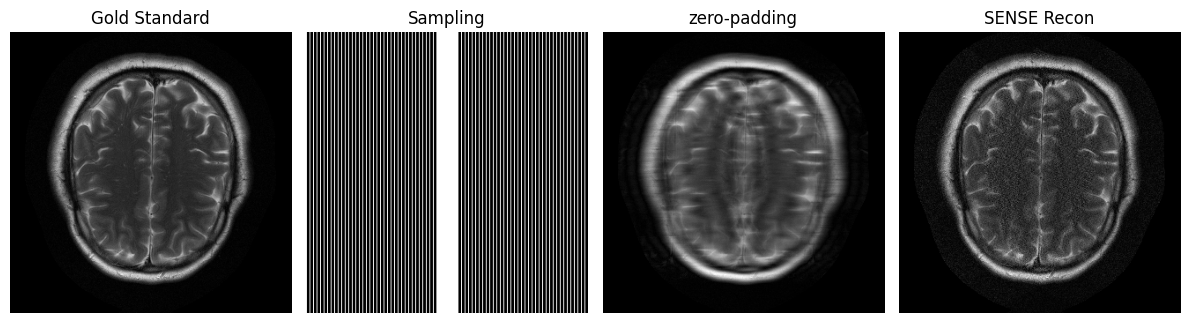

SENSE. Acc: 3.27x, NRMSE: 0.217, zp_NRMSE: 0.214
SENSE-LORAKS Reconstruction
iter 1, t: 1.16e-01
iter 2, t: 1.93e-02
iter 3, t: 1.20e-02
iter 4, t: 8.46e-03
iter 5, t: 6.28e-03
Done. Acc: 3.27x, NRMSE: 0.139, zp_NRMSE: 0.214


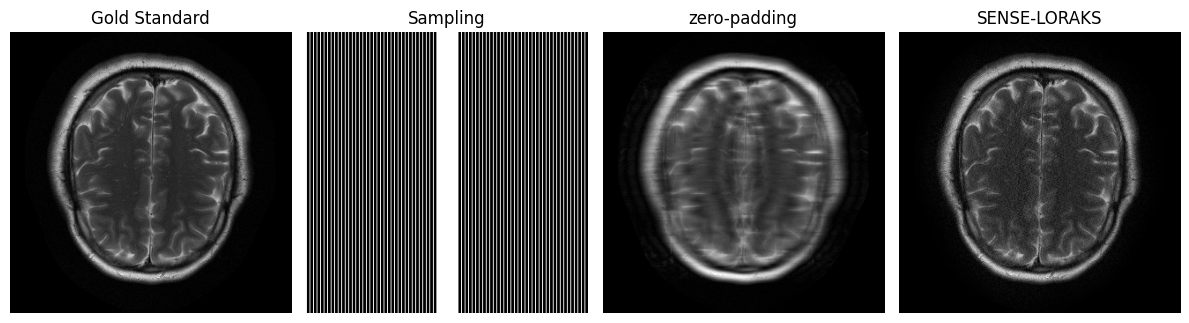

In [12]:



# -------------------------- SENSE Initialization ------------------------------
# def A(x):
#     """
#     Define SENSE forward model: A
#     """
#     return kMask * ft2_np(coil_sens * x[...,None])

def Ah(x):
    """
    Hermitian adjoint of SENSE forward model: A^H
    """
    return (coil_sens.conj()*ift2_np(kMask * x)).sum(-1)

def AhA(x):
    """
    Compute A^H A x: SENSE normal equation operator.
    """
    return (coil_sens.conj()*ift2_np(kMask * ft2_np(coil_sens * x[...,None]))).sum(-1)

def B(x):
    """
    Define multi-channel encoding: B
    """
    return ft2_np(coil_sens * x[...,None])

def Bh(x):
    """
    Hermitian adjoint of B: B^H
    """
    return (coil_sens.conj()*ift2_np(x)).sum(-1)

def VC_aug(kData):
    """
    Apply Virtual Conjugate Coil (VCC) augmentation to kspace data
    """
    _, _, C = kData.shape

    kData_vcc = np.flip(np.flip(np.conj(kData), axis=0), axis=1)

    augmented_kData = np.concatenate((kData, kData_vcc), axis=-1)

    return augmented_kData

def VC_h(augmented):
    """
    Hermitian adjoint of VCC augmentation
    """
    _, _, doubled_C = augmented.shape
    C = doubled_C // 2

    recon_orig = augmented[:, :, :C]
    recon_vcc = augmented[:, :, C:]
    recon_reverted = np.conj(np.flip(np.flip(recon_vcc, axis=0), axis=1))
    recon_combined = recon_orig + recon_reverted

    return recon_combined

def CG(AhA, Ahd, data_size = (nx, ny), max_iter=20, tol=1e-6, verbose=True):
    """
    Conjugate gradient solver for Ax = b using function handle AhA for A^H@A and vector A^H@d.

    Parameters:
    - AhA: function handle AhA(x) representing A^H @ A @ x
    - Ahd: right-hand side vector (A^H @ d)
    - data_size: dimensions of the output
    - max_iter: maximum number of iterations
    - tol: tolerance for residual norm
    - verbose: if True, print per-iteration logs

    Returns:
    - recon: reconstructed image reshaped to [nx, ny]
    """
    x = np.zeros(data_size, dtype=np.complex64)  # initial guess (flattened)
    r = Ahd - AhA(x)
    p = r.copy()
    rsold = np.vdot(r, r)  # inner product r'*r

    for it in range(1, max_iter + 1):
        z = AhA(p)
        alpha = rsold / np.vdot(p, z)
        x += alpha * p
        r -= alpha * z
        rsnew = np.vdot(r, r)

        residue = np.sqrt(rsnew).real

        if verbose:
            if it % 10 == 0:
                print(f"iter {it}, residue: {residue:.4e}")

        if residue < tol:
            break

        p = r + (rsnew / rsold) * p
        rsold = rsnew

    recon = x.reshape(data_size)
    return recon#, {"iterations": iter, "residue": residue}

# ideal (Gold Standard) and zero-padded solutions
ideal = (coil_sens.conj()*ift2_np( kData )).sum(2) / ((abs(coil_sens)**2).sum(2)+np.finfo(float).eps);
zp = (coil_sens.conj()*ift2_np( kData*kMask )).sum(2) / ((abs(coil_sens)**2).sum(2)+np.finfo(float).eps);

# Compute SENSE initial reconstruction
print("SENSE Reconstruction")
Ahd = Ah(kdata)
sense = CG(AhA, Ahd, verbose=False)

# Visualize SENSE results
plt.figure(figsize=(12, 4))
plt.subplot(1, 4, 1); show(abs(ideal), "Gold Standard")
plt.subplot(1, 4, 2); show(kMask[...,0], "Sampling")
plt.subplot(1, 4, 3); show(abs(zp), "zero-padding")
plt.subplot(1, 4, 4); show(abs(sense), "SENSE Recon")
plt.tight_layout()
plt.show()

error = LA.norm(sense - ideal) / LA.norm(ideal)
zp_error = LA.norm(zp - ideal) / LA.norm(ideal)
print(f"SENSE. Acc: {acc:.2f}x, NRMSE: {error:.3f}, zp_NRMSE: {zp_error:.3f}")

# ------------------------ SENSE-LORAKS Initialization -------------------------
if VCC:
    weight = VC_h(Mtok(ktoM(VC_aug(kdata), R), (nx, ny, 2*nc), R)[1])
else:
    weight = Mtok(ktoM(kdata, R), (nx, ny, nc), R)[1]

z = sense

# ---------------- SENSE-LORAKS Reconstruction ----------------
print("SENSE-LORAKS Reconstruction")

for i in range(1, max_iter+1):
    z_prev = z.copy()

    # Build LORAKS matrix
    if VCC:
        CC = ktoM(VC_aug(B(z)), R)
    else:
        CC = ktoM(B(z), R)

    # Low-rank projection of LORAKS matrix
    Ucc,_,_ = svdsecon(CC, k=r_C)

    # Define iterative update forward operator phi
    if VCC:
        phi = lambda x: (coil_sens.conj()*ift2_np( (kMask + lambda_ * weight) * ft2_np(coil_sens * x[...,None]))).sum(-1) \
            - lambda_ * Bh(VC_h(Mtok( (Ucc@(Ucc.conj().T @ ktoM(VC_aug(B(x)), R))), (nx,ny,2*nc), R)[0]))
    else:
        phi = lambda x: (coil_sens.conj()*ift2_np( (kMask + lambda_ * weight) * ft2_np(coil_sens * x[...,None]))).sum(-1) \
            - lambda_ * Bh(Mtok( (Ucc@(Ucc.conj().T @ ktoM(B(x), R))), (nx,ny,nc), R)[0])

    # Update solution via CG
    z = CG(phi, Ahd, verbose=False )

    t = LA.norm(z_prev - z) / LA.norm(z)

    print(f"iter {i}, t: {t:.2e}")

    if t < tol:
        print(f"Converged at iter {i}, t: {t:.2e}")
        break

recon = z

# ------------------------ Reconstruction Error --------------------------------
error = LA.norm(recon - ideal) / LA.norm(ideal)
zp_error = LA.norm(zp - ideal) / LA.norm(ideal)
print(f"Done. Acc: {acc:.2f}x, NRMSE: {error:.3f}, zp_NRMSE: {zp_error:.3f}")

# ---------------------------- Visualization -----------------------------------
plt.figure(figsize=(12, 4))
plt.subplot(1, 4, 1); show(abs(ideal), "Gold Standard")
plt.subplot(1, 4, 2); show(kMask[...,0], "Sampling")
plt.subplot(1, 4, 3); show(abs(zp), "zero-padding")
plt.subplot(1, 4, 4); show(abs(recon), "SENSE-LORAKS")
plt.tight_layout()
plt.show()


Equivalence variables names and plots : <br>
ideal  == "Gold Standard"; kMask[...,0] == "Sampling"; abs(zp) == "zero-padding"; abs(recon) == "SENSE-LORAKS"

## focus on error calculation
What is ground truth image? not rss.

In [ ]:
# ideal (Gold Standard) and zero-padded solutions

ideal = (coil_sens.conj()*ift2_np( kData )).sum(2) / ((abs(coil_sens)**2).sum(2)+np.finfo(float).eps);
zp = (coil_sens.conj()*ift2_np( kData*kMask )).sum(2) / ((abs(coil_sens)**2).sum(2)+np.finfo(float).eps);

# error calculation with reference to gold standard
error = LA.norm(sense - ideal) / LA.norm(ideal)
zp_error = LA.norm(zp - ideal) / LA.norm(ideal)

